# 2. Spectro-astrometry: following the donor's reflection around the orbit

Notebook 1 showed that neither binary is resolved, and that the donor's echo in time is weak. An interferometer can do something a photon counter cannot: every photon's fringe phase says a little about where it came from. The donor's reflection is a larger share of the light in the Fe band (5.9-7 keV) than in the continuum, so the Fe-band centroid sits slightly towards the donor, and moves with it around the orbit. Here we ask how well the bundled array measures that.

We go in three steps: how precisely one photon locates an unresolved source (measured with XRISALIS), how large the Fe-band shift is around the orbit (from the models), and what a campaign of 100 ks visits at eight orbital phases recovers (simulated through XRISALIS, and fitted with the orbital pattern plus a free constant offset, which absorbs any steady instrumental offset between the bands).

Positions come from `xrisalis.recipes.point_position`: the peak of the coherence-weighted dirty image, found from the photons' phases directly (no pixels), which for structure much smaller than the beam is the band's brightness-weighted centroid. Its error comes from the photons' own phase scatter (a test in XRISALIS checks it against repeated simulations).

In [1]:
import warnings

import numpy as np
import matplotlib.pyplot as plt

import xrisalis as xs
from xrisalis import recipes

from lmxrbs_xri import CYGX2, GRS1915
from lmxrbs_xri.astrometry import centroid, fold_fit

warnings.filterwarnings("ignore")
SETUP = recipes.bundled()
TARGETS = (GRS1915, CYGX2)
FE = (5.9, 7.0)
CONT = {"grs": (3.0, 5.0), "cx2": (1.0, 4.0)}   # GRS 1915+105 is absorbed below ~2 keV

 Solar Abundance Vector set to angr:  Anders E. & Grevesse N. Geochimica et Cosmochimica Acta 53, 197 (1989)
 Cross Section Table set to vern:  Verner, Ferland, Korista, and Yakovlev 1996


## How well one photon locates the source

Here we observe a point source with each system's own (absorbed) spectrum and real brightness for a few hundred seconds, and measure its position from the photons in each detected-energy band. We quote σ₁, the one-axis precision per photon (the position error times √N). It is set by the fringe spacing λ/B of the baselines that still have area at that energy, and by how much of the fringe contrast survives: photons far out in the fringe pattern decohere with the detector's energy resolution, and the matched-filter weights count them less.

Compton reflection from neutral medium.
See help for details.
If you use results of this model in a paper,
please refer to Magdziarz & Zdziarski 1995 MNRAS, 273, 837


GRS 1915+105: 0.5-1 keV 24012 uas (16100 photons), 1-2 keV 587 uas (209275 photons), 2-4 keV 571 uas (610008 photons), 4-5.9 keV 503 uas (296337 photons), 5.9-7 keV 445 uas (80072 photons), 7-10 keV 495 uas (45720 photons); continuum band 3-5 keV 517 uas
Cyg X-2: 0.5-1 keV 887 uas (359822 photons), 1-2 keV 575 uas (1012762 photons), 2-4 keV 584 uas (472828 photons), 4-5.9 keV 506 uas (150043 photons), 5.9-7 keV 486 uas (30323 photons), 7-10 keV 483 uas (18742 photons); continuum band 1-4 keV 585 uas


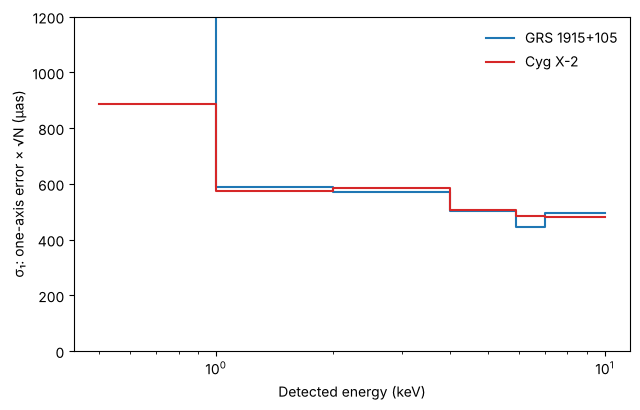

In [2]:
bands = [(0.5, 1.0), (1.0, 2.0), (2.0, 4.0), (4.0, 5.9), (5.9, 7.0), (7.0, 10.0)]
sigma1, sigma1_cont = {}, {}
for t, t_exp in zip(TARGETS, (600.0, 300.0)):
    m = t.scene(0.5).render()
    pt = recipes.point_source_like(m, recipes.total_spectrum(m).photon_flux())  # absorbed flux
    ph = xs.generate_photons(xs.XrimodelSource(pt), SETUP.arf, t_exp, seed=1)
    ev = xs.redistribute(ph, SETUP.instrument, SETUP.rmf, seed=2)
    rows = []
    for b in bands:
        try:
            east, north, cov, n = recipes.point_position(ev, SETUP, energy_kev=b)
        except (ValueError, np.linalg.LinAlgError):
            rows.append((np.nan, 0))
            continue
        rows.append((np.sqrt(0.5 * np.trace(cov) * n), n))
    sigma1[t.name] = np.array(rows)
    _, _, cov, n = recipes.point_position(ev, SETUP, energy_kev=CONT[t.name])
    sigma1_cont[t.name] = np.sqrt(0.5 * np.trace(cov) * n)
    del ev, ph

fig, ax = plt.subplots(figsize=(6.5, 4.2))
mid = [0.5 * (a + b) for a, b in bands]
for t, col in zip(TARGETS, ("C0", "C3")):
    s = sigma1[t.name][:, 0]
    ax.step([b[0] for b in bands] + [bands[-1][1]], np.r_[s, s[-1]], where="post", color=col, label=t.label)
ax.set_xscale("log"); ax.set_ylim(0, 1200)   # GRS 1915+105 below 1 keV (absorbed, few photons) is off the scale
ax.set_xlabel("Detected energy (keV)"); ax.set_ylabel("σ₁: one-axis error × √N (µas)")
ax.legend(frameon=False)
fig.tight_layout()
for t in TARGETS:
    print(t.label + ": " + ", ".join(f"{b[0]:g}-{b[1]:g} keV {s:.0f} uas ({int(n)} photons)"
                                     for b, (s, n) in zip(bands, sigma1[t.name]))
          + f"; continuum band {CONT[t.name][0]:g}-{CONT[t.name][1]:g} keV {sigma1_cont[t.name]:.0f} uas")

These are an order of magnitude worse than the λ/(2πB) of the longest baselines (~40 µas at 1 keV for 1 m): the per-photon fringe contrast is low, because most photons land many fringe orders from the centre of the pattern, where the detector's energy resolution decoheres them. In the Fe band only the four shortest baselines (≤ 0.37 m) have area.

## The signal around the orbit

Here we render each system at 16 phases and show the model's Fe-band centroid relative to the continuum centroid, in counts through the bundled ARF: on the sky (left; the grey line points from the compact object to the donor's centre, scaled down) and its size around the orbit (right). The compact object, the disc's thermal light and its inner Fe line all sit at the origin and only dilute the shift.

GRS 1915+105: largest shift 0.166 uas; Fe band 144 counts/s, continuum 863 counts/s
Cyg X-2: largest shift 0.108 uas; Fe band 107 counts/s, continuum 4837 counts/s


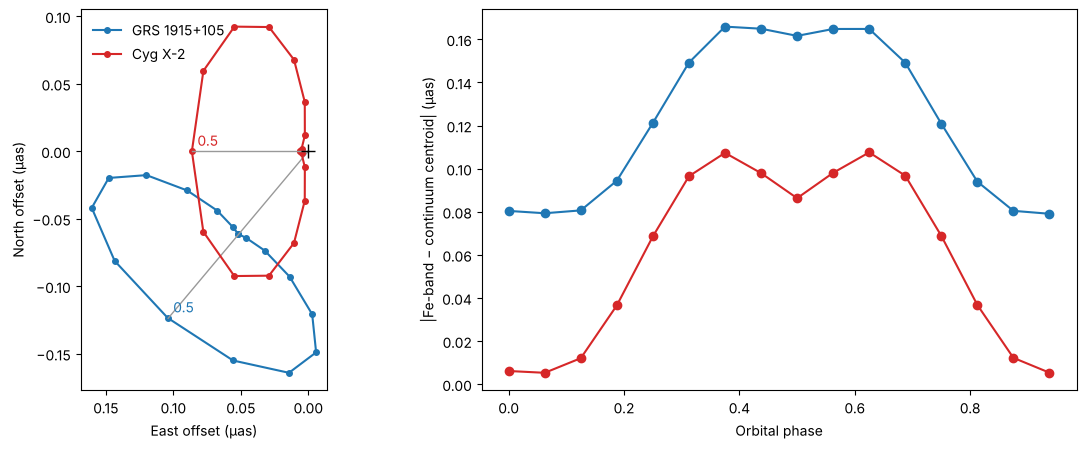

In [3]:
phases = np.linspace(0.0, 1.0, 17)[:-1]
track = {}
for t in TARGETS:
    rows = []
    for ph in phases:
        m = t.scene(ph).render()
        fe, co = centroid(m, FE), centroid(m, CONT[t.name])
        rows.append((ph, fe[0] - co[0], fe[1] - co[1], fe[2], co[2], *t.donor_sky(ph)))
    track[t.name] = np.array(rows)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for t, col in zip(TARGETS, ("C0", "C3")):
    r = track[t.name]
    ax[0].plot(np.r_[r[:, 1], r[0, 1]], np.r_[r[:, 2], r[0, 2]], "o-", color=col, ms=4, label=t.label)
    k = 8
    scale = np.hypot(r[k, 1], r[k, 2]) / np.hypot(r[k, 5], r[k, 6])
    ax[0].plot([0, r[k, 5] * scale], [0, r[k, 6] * scale], color="0.6", lw=1)
    ax[0].annotate("0.5", (r[k, 1], r[k, 2]), color=col, textcoords="offset points", xytext=(4, 4))
    ax[1].plot(r[:, 0], np.hypot(r[:, 1], r[:, 2]), "o-", color=col, label=t.label)
ax[0].plot(0, 0, "+", color="k", ms=10)
ax[0].invert_xaxis(); ax[0].set_aspect("equal")
ax[0].set_xlabel("East offset (µas)"); ax[0].set_ylabel("North offset (µas)")
ax[0].legend(frameon=False)
ax[1].set_xlabel("Orbital phase"); ax[1].set_ylabel("|Fe-band − continuum centroid| (µas)")
fig.tight_layout()
for t in TARGETS:
    r = track[t.name]
    print(f"{t.label}: largest shift {np.hypot(r[:, 1], r[:, 2]).max():.3f} uas; Fe band {r[:, 3].mean():.0f} counts/s, "
          f"continuum {r[:, 4].mean():.0f} counts/s")

The shift is a tenth of a micro-arcsecond: the donor's centre is 7-22 µas from the compact object, but its reflection is only ~1% of the Fe-band counts. GRS 1915+105's shift does not vanish at phase 0 because its large disc reflects more from one side than the other; that part is the same at every phase, so the fit's constant takes it.

## What a folded campaign needs

Here we forecast the significance of the orbital pattern's amplitude (1 for the model) for visits at eight phases, from photon noise alone: in each visit the Fe-band centroid has error σ₁(Fe)/√N_Fe per axis and the continuum's σ₁(cont)/√N_cont, and the fit has three parameters (the amplitude and a constant offset in East and North).

GRS 1915+105: 3 sigma needs ~383 ks per visit, 3.1 Ms in all
Cyg X-2: 3 sigma needs ~604 ks per visit, 4.8 Ms in all


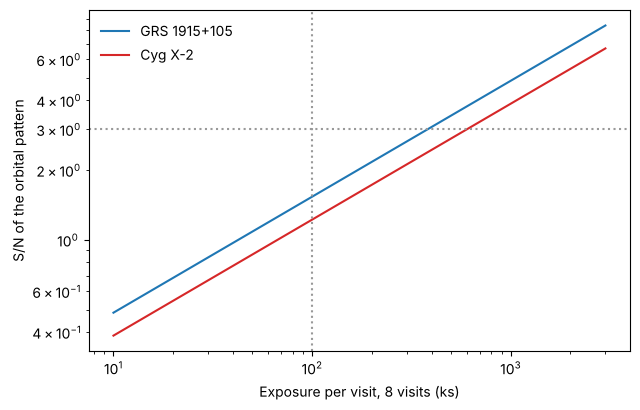

In [4]:
visits = np.geomspace(1e4, 3e6, 60)   # s per visit
fig, ax = plt.subplots(figsize=(6.5, 4.2))
need = {}
for t, col in zip(TARGETS, ("C0", "C3")):
    r = track[t.name][::2]                       # eight phases
    s_fe = sigma1[t.name][bands.index(FE), 0]
    s_co = sigma1_cont[t.name]
    snr = []
    for v in visits:
        covs = [np.eye(2) * (s_fe**2 / (ri[3] * v) + s_co**2 / (ri[4] * v)) for ri in r]
        snr.append(1 / fold_fit(np.zeros((len(r), 2)), covs, r[:, 1:3])[1])
    snr = np.array(snr)
    need[t.name] = np.interp(3.0, snr, visits)
    ax.loglog(visits / 1e3, snr, color=col, label=t.label)
ax.axvline(100, color="0.6", ls=":"); ax.axhline(3, color="0.6", ls=":")
ax.set_xlabel("Exposure per visit, 8 visits (ks)"); ax.set_ylabel("S/N of the orbital pattern")
ax.legend(frameon=False)
fig.tight_layout()
for t in TARGETS:
    print(f"{t.label}: 3 sigma needs ~{need[t.name] / 1e3:.0f} ks per visit, {8 * need[t.name] / 1e6:.1f} Ms in all")

## A simulated campaign: eight 100 ks visits

Here we load the campaign simulated by `scripts/simulate_campaign.py`: for each system, eight 100 ks visits centred on phases 0, 0.125, ... 0.875. Each visit is simulated through XRISALIS in four 25 ks pieces rendered at their own phase (Cyg X-2 moves 0.12 in phase during a visit), drawing only the photons that can land in the Fe band, and its Fe-band position is measured from all of their fringe phases. The continuum band has ~30-50 times more photons and is too large to simulate in full; we use the model's continuum centroid as the reference and add a random error with the size its photons would give (σ₁(cont) measured on a 200 s stretch). The fit is the same as above: amplitude times the model's pattern, plus a constant offset.

GRS 1915+105: amplitude 0.53 +- 0.74 (model 1; S/N expected 1.4); constant (-0.001, 0.053) uas; chi2 18.4 for 13 dof; Fe-band position error per visit 0.136 uas
Cyg X-2: amplitude 1.98 +- 0.89 (model 1; S/N expected 1.1); constant (0.032, 0.060) uas; chi2 3.7 for 13 dof; Fe-band position error per visit 0.156 uas


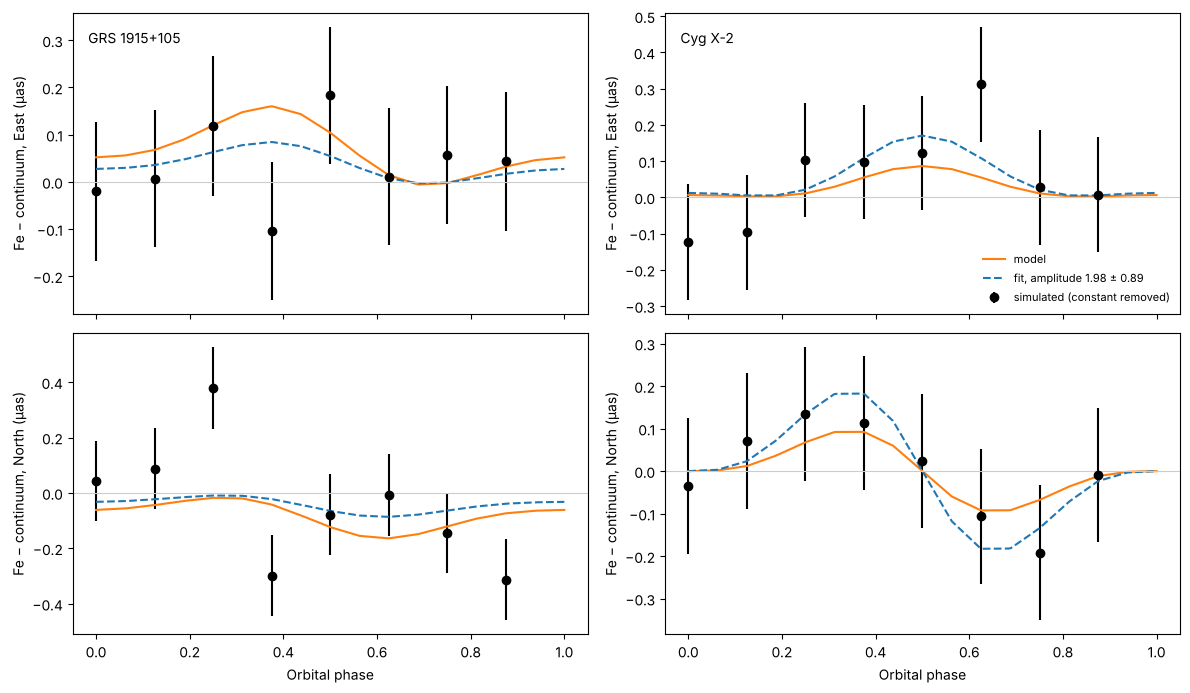

In [5]:
rng = np.random.default_rng(7)
fig, ax = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for j, t in enumerate(TARGETS):
    d = np.load(f"../data/campaign_{t.name}.npz")
    r = d["rows"]
    ph, n = r[:, 0], r[:, 7]
    cov_fe = r[:, 3:7].reshape(-1, 2, 2)
    s_co = float(np.mean(d["cont_sigma1"]))
    var_co = s_co**2 / (float(d["cont_rate"]) * float(d["visit"]))
    cont = r[:, 10:12] + rng.normal(0.0, np.sqrt(var_co), (len(r), 2))
    off = r[:, 1:3] - cont
    covs = cov_fe + np.eye(2) * var_co
    pattern = r[:, 8:10] - r[:, 10:12]
    s, ds, const, chi2, dof = fold_fit(off, covs, pattern)
    print(f"{t.label}: amplitude {s:.2f} +- {ds:.2f} (model 1; S/N expected {1 / ds:.1f}); "
          f"constant ({const[0]:.3f}, {const[1]:.3f}) uas; chi2 {chi2:.1f} for {dof} dof; "
          f"Fe-band position error per visit {np.sqrt(cov_fe[:, 0, 0]).mean():.3f} uas")
    pf = np.linspace(0, 1, 200)
    tr = track[t.name]
    model = np.column_stack([np.interp(pf, np.r_[tr[:, 0], 1], np.r_[tr[:, k], tr[0, k]]) for k in (1, 2)])
    for i, lab in enumerate(("East", "North")):
        a = ax[i, j]
        a.errorbar(ph, off[:, i] - const[i], np.sqrt(covs[:, i, i]), fmt="o", color="k", label="simulated (constant removed)")
        a.plot(pf, model[:, i], color="C1", label="model")
        a.plot(pf, s * model[:, i], color="C0", ls="--", label=f"fit, amplitude {s:.2f} ± {ds:.2f}")
        a.axhline(0, color="0.8", lw=0.8)
        a.set_ylabel(f"Fe − continuum, {lab} (µas)")
    ax[0, j].text(0.03, 0.9, t.label, transform=ax[0, j].transAxes)
    ax[1, j].set_xlabel("Orbital phase")
ax[0, 1].legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()

Neither campaign detects the orbital pattern, as the forecast said: the fitted amplitudes are 0.5 ± 0.7 for GRS 1915+105 and 2.0 ± 0.9 for Cyg X-2, both consistent with the model's 1 and with zero, and their errors are the forecast's (S/N 1.4 and 1.1 for eight 100 ks visits). The simulated positions scatter as their quoted errors say for GRS 1915+105 (χ² 18 for 13 degrees of freedom); for Cyg X-2 the χ² is low (3.7 for 13, p ≈ 0.5%), so its quoted errors may be somewhat pessimistic, which repeated campaigns would show. The fitted constants (~0.05 µas) are the part of the pattern that does not change with phase.

With the bundled array, a 3σ detection needs about 3 Ms (GRS 1915+105) and 5 Ms (Cyg X-2) spread over the orbit. The limit is the per-photon precision of ~450-500 µas in the Fe band: twice the fringe contrast, or long baselines that keep their area at 6-7 keV, would cut these exposures by four or more.

Caveats: the continuum reference is not simulated photon by photon (its error, from its measured precision, is 3% of each visit's variance for Cyg X-2 and 14% for GRS 1915+105); the instrument has no energy-dependent systematics here; and the sources keep the same state, spectrum and variability-averaged flux at every visit.